# Activity 1 Scenario: Simple Regression - Underfitting vs. Overfitting You’re trying to fit a curve to data points. A very simple model might underfit, while a very complex one might overfit

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

In [2]:
np.random.seed(0)
X=np.sort(5*np.random.rand(80,1),axis=0)
y=np.sin(X).ravel()+np.random.normal(0,0.5,80)

In [3]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.3,random_state=42
)

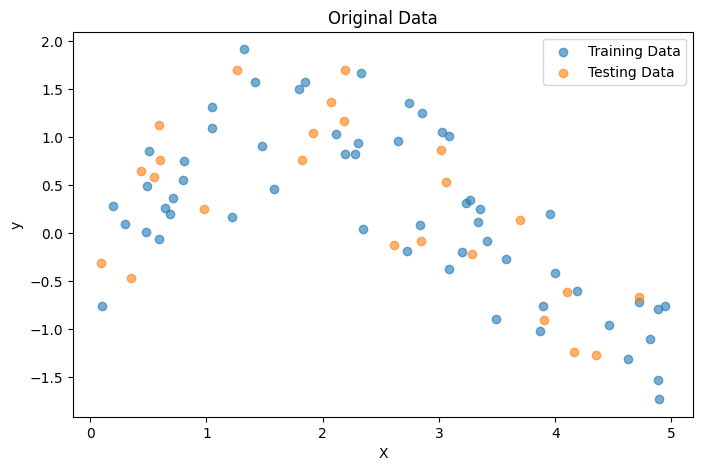

In [4]:
plt.figure(figsize=(8,5))
plt.scatter(X_train,y_train,label='Training Data',alpha=0.6)
plt.scatter(X_test,y_test,label='Testing Data',alpha=0.6)
plt.title('Original Data')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [5]:
model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
mean_squared_error(y_test,y_pred)

0.5333715987875559

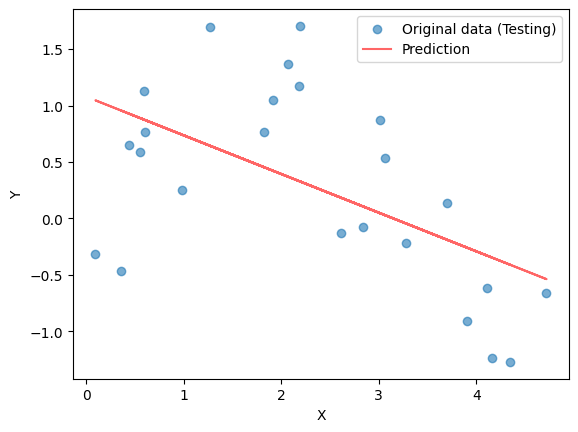

In [6]:
plt.figure()
plt.scatter(X_test,y_test,label='Original data (Testing)',alpha=0.6)
plt.plot(X_test,y_pred,label='Prediction',alpha=0.6,color='red')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()


The straight line does not capture the data well as the actual data point is far from the prediction line . This is an example of under fittling because the prediction line is not able to capture the non-linear trend in the data and over simplifies the output.

In [7]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

In [8]:
poly_model=make_pipeline(PolynomialFeatures(degree=20),LinearRegression())
poly_model.fit(X_train,y_train)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=20)),
                ('linearregression', LinearRegression())])

In [9]:
y_pred_test=poly_model.predict(X_test)
y_pred_train=poly_model.predict(X_train)

In [10]:
print('Mean Squared Error (Training):')
mean_squared_error(y_train,y_pred_train)

Mean Squared Error (Training):


0.19278054099038275

In [11]:
print('Mean Squared Error(Testing):')
mean_squared_error(y_test,y_pred_test)

Mean Squared Error(Testing):


0.29394682964830204

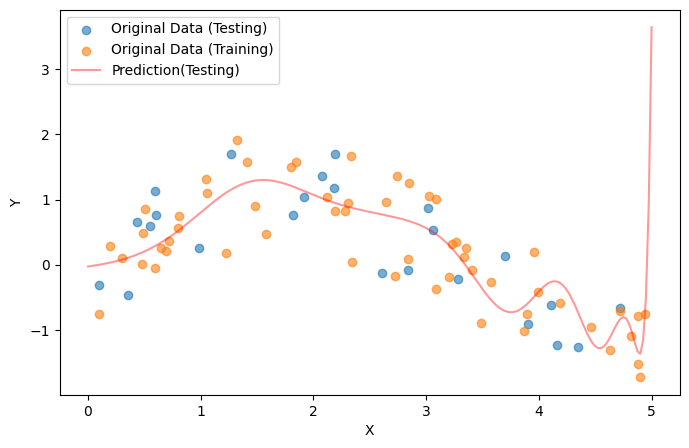

In [12]:
plt.figure(figsize=(8,5))
plt.scatter(X_test,y_test,alpha=0.6,label='Original Data (Testing)')
plt.scatter(X_train,y_train,alpha=0.6,label='Original Data (Training)')
X_plot=np.linspace(0,5,200).reshape(-1,1)
plt.plot(X_plot,poly_model.predict(X_plot),label='Prediction(Testing)',alpha=0.4,color='red')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

It is an example of overfitting because the polynomial model is capturing even the noise in the data. a small uphill or downhill in the data poins is reflected in the preduction curve in the diagram

# **Activity 2** Scenario: Data Separability - Linear vs. Non-linear Boundaries Some classification problems can be solved with a straight line, while others need more complex curves

In [13]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

In [14]:
X_linear,y_linear=make_classification(
    n_samples=100,n_features=2,n_informative=2,n_redundant=0,
    n_clusters_per_class=1,random_state=4,class_sep=1.5
    ) #high class seperation for linear seperability


In [15]:
X_linear

array([[-1.95911997,  0.77418673],
       [-1.90811432,  1.2656503 ],
       [-1.30951052, -2.15609373],
       [-2.62064621, -1.16898039],
       [-1.97889457,  0.25970564],
       [-0.28507733, -1.44078319],
       [-1.38723533,  1.77909021],
       [-2.19760226,  0.7121016 ],
       [-1.45780633, -1.96767931],
       [-2.60161186,  0.44822613],
       [-1.07325084, -1.85015894],
       [-0.178807  , -0.52985844],
       [-3.0735914 , -0.37730766],
       [-1.64876618,  1.11554048],
       [-1.88262269,  0.15768775],
       [-0.59595018, -0.90346164],
       [-1.26692811,  1.56812167],
       [-2.60942592,  0.26836427],
       [ 0.05893733, -2.5168051 ],
       [-1.92934539, -2.3439296 ],
       [-2.34899277, -0.20715603],
       [-1.50962409,  1.64260845],
       [-2.30151453, -2.26488978],
       [-0.08771643,  2.87044324],
       [-2.46672657, -0.95787397],
       [-2.42263976,  0.42183215],
       [-1.18467409,  1.81431729],
       [-2.22232541,  0.84032824],
       [-2.11710431,

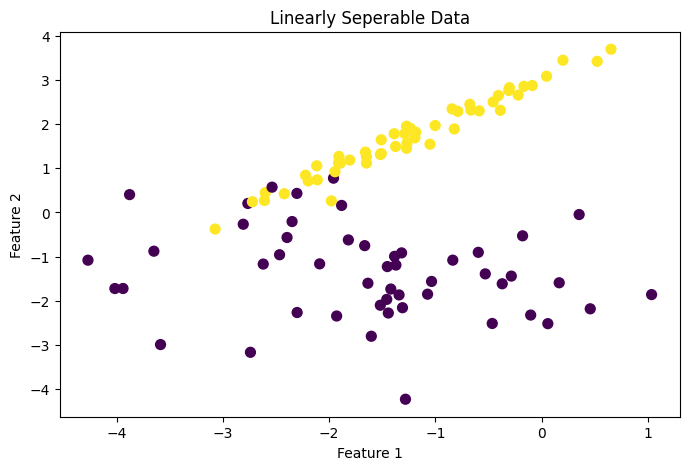

In [16]:
plt.figure(figsize=(8,5))
plt.scatter(X_linear[:,0],X_linear[:,1],c=y_linear,s=50)
plt.title("Linearly Seperable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [18]:
model=LogisticRegression()
X_train,X_test,y_train,y_test=train_test_split(
    X_linear,y_linear,test_size=0.3)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
accuracy_score(y_test,y_pred)

0.9333333333333333

Yes, the data is linearly seperable as we can make a line in a manner that vast majority of the data points of each classes lie together and and are at different sides of the line. The logistic regression model , a linear classifier, It's  high accuracy of 93% also shown that the data is linearly seperable.

In [56]:
from sklearn.datasets import make_circles
X_nonlinear,y_nonlinear=make_circles(
    n_samples=100,noise=0.1,factor=0.7,random_state=1
)

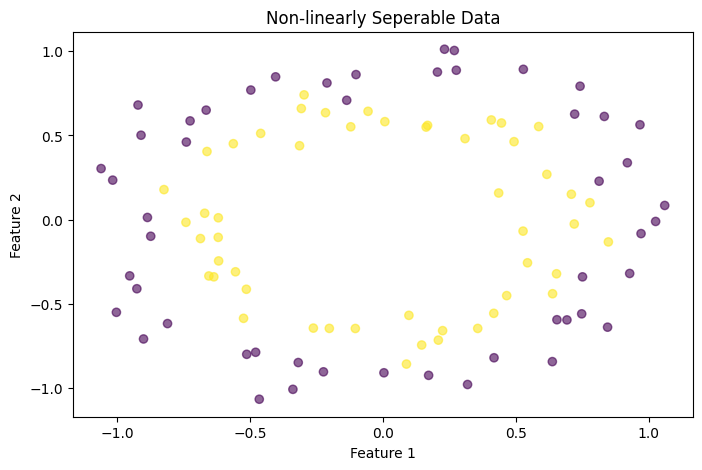

In [57]:
plt.figure(figsize=(8,5))
plt.scatter(X_nonlinear[:,0],X_nonlinear[:,1],
         alpha=0.6,c=y_nonlinear)
plt.title('Non-linearly Seperable Data')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [58]:
model=LogisticRegression()
X_train,X_test,y_train,y_test=train_test_split(
    X_nonlinear,y_nonlinear,test_size=0.3)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
accuracy_score(y_test,y_pred)

0.3333333333333333

No, a straight line cannot Effectively seperate these 2 classes as the data is present in seperate concentric circles. A classifier such as SVM which can seperate data non linearly would be a better option.
